# Day 17: Hours of daylight in UK

Collaborative map (day 16) to show summer vs winter side by side. 

In [46]:
import geopandas as gpd
import numpy as np
from shapely.geometry import box
import matplotlib.pyplot as plt
from shapely.geometry import Point
import pandas as pd

from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

## Data processing

In [13]:
# Calculate daylength by latitude 
def daylength_hours(lat_deg, declination_deg=23.44, sun_alt_deg=-0.833):
    # sun_alt_deg=-0.833 accounts for refraction + solar disc
    lat = np.radians(lat_deg)
    dec = np.radians(declination_deg)
    alt = np.radians(sun_alt_deg)
    cos_h = (np.sin(alt) - np.sin(lat) * np.sin(dec)) / (np.cos(lat) * np.cos(dec))
    return 24 / np.pi * np.arccos(np.clip(cos_h, -1, 1))

# Load UK outline in WGS84 projection
world = gpd.read_file(
    "https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_0_countries.zip"
)
uk = world[world["ADM0_A3"] == "GBR"].to_crs(4326)
uk = uk.explode(index_parts=False)  # split multipolygon into islands

In [91]:
# Create latitude bands
step = 0.25     #0.25 degree = ~28km = 40 bands
minx, miny, maxx, maxy = uk.total_bounds
lat_edges = np.arange(np.floor(miny / step) * step, maxy + step, step)

bands = gpd.GeoDataFrame(
    {
        "lat_mid": (lat_edges[:-1] + lat_edges[1:]) / 2,
        "geometry": [
            box(minx - 1, lo, maxx + 1, hi)
            for lo, hi in zip(lat_edges[:-1], lat_edges[1:])
        ],
    },
    crs=4326,
)
bands["hours"] = daylength_hours(bands["lat_mid"])

# Clip bands to the UK shape
uk_union = uk.unary_union  # use .unary_union on older geopandas
bands["geometry"] = bands.geometry.intersection(uk_union)
bands = bands[~bands.geometry.is_empty]

#Reproject to British National Grid
bands_bng = bands.to_crs(27700)

In [101]:
# Places
places = {
    'London':     [51.5074, -0.1278],
    'Manchester': [53.4808, -2.2426],
    'Edinburgh':  [55.9533, -3.1883],
    'Penzance': [50.1179, -5.5415],
    'Shetland': [60.3488, -1.2305],
}
places = pd.DataFrame.from_dict(places, orient='index', columns=['lat', 'lon'])
geometry = [Point(xy) for xy in zip(places['lon'], places['lat'])]
places = gpd.GeoDataFrame(places, crs='EPSG:4326', geometry=geometry)

# daylength at each city, reusing the function from before
places['hours'] = daylength_hours(places['lat'])

# reproject to British National Grid to match the map
places = places.to_crs(27700)

## Visualisation

In [ ]:
def format_hours(hours):
    h, m = divmod(round(hours * 60), 60)
    return f"{h}h {m:02d}m"

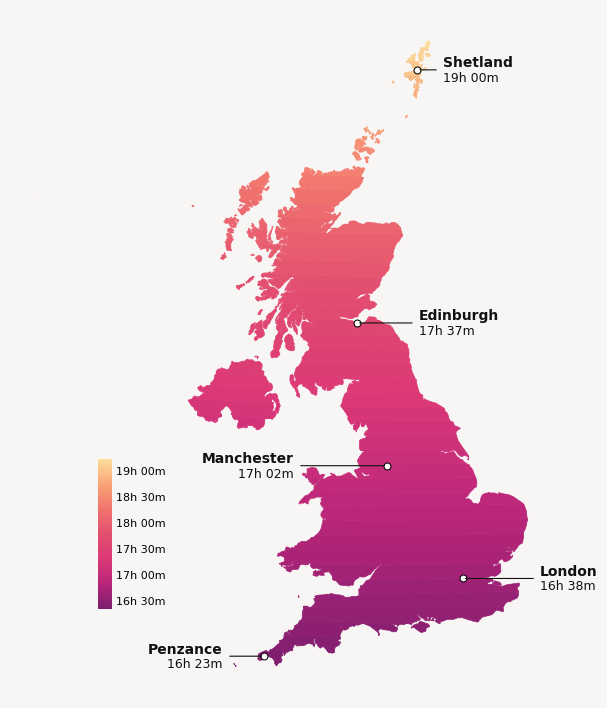

In [114]:
# Plot
fig, ax = plt.subplots(figsize=(7, 10))
fig.set_facecolor("#F8F5F5")

#colormap
from pypalettes import load_cmap
cmap = load_cmap("SunsetDark", reverse=True, cmap_type="continuous")
vmin, vmax = bands_bng["hours"].min(), bands_bng["hours"].max()
norm = Normalize(vmin, vmax)

#plot bands
bands_bng.plot(
    column="hours", cmap=cmap, ax=ax,
    edgecolor="face", linewidth=0.5,
    legend=False,
)


#plot place labels
places.plot(ax=ax, markersize=25, zorder=3, color='white', edgecolor='black',
             linewidth=0.75)
# label offsets in metres (dx, dy) from each marker
label_offsets = {
    'London':     (150_000,   0, 'left'),    
    'Manchester': (-180_000,  0, 'right'), 
    'Edinburgh':  (120_000,  0, 'left'),
    'Penzance': (-80_000, 0, 'right'),
    'Shetland':   (50_000,   0, 'left'), 
}

line_kw = dict(arrowstyle='-', color='#111111', linewidth=0.8, shrinkA=3, shrinkB=2)

for name, row in places.iterrows():
    dx, dy, ha = label_offsets[name]
    x, y = row.geometry.x, row.geometry.y
    tx, ty = x + dx, y + dy

    # bold name, line to the marker
    ax.annotate(name, xy=(x, y), xytext=(tx, ty),
                fontsize=10, fontweight='bold', ha=ha, va='bottom', color='#111111',
                arrowprops=dict(**line_kw, relpos=(0 if ha == 'left' else 1, 0)),
                zorder=4)
    # regular-weight hours below the name
    ax.text(tx, ty - 3000, format_hours(row['hours']),
            fontsize=9, ha=ha, va='top', color='#111111', zorder=4)


#add legend
cbaxes = fig.add_axes([0.25, 0.24, 0.02, 0.15])  
cmappable = ScalarMappable(norm=norm, cmap=cmap)
cb = plt.colorbar(cmappable, cax=cbaxes, orientation='vertical',
                   drawedges=False)
cb.outline.set_visible(False)
cbaxes.tick_params(size=0, labelsize=8)

ticks = np.arange(np.ceil(vmin * 2) / 2, vmax, 0.5)
cb.set_ticks(ticks)
cb.set_ticklabels([format_hours(t) for t in ticks])

ax.set_axis_off()

#export
#plt.savefig("daylight-summer.svg")
#plt.savefig("daylight-summer.png", bbox_inches='tight', pad_inches=0.65, dpi=300)

plt.show()

## Playground

Colour palettes

##### Winter
moth
naturaleza


pinkYl
SunsetDark
